# Onafhankelijke E2-schaal · volledige 100-epochtraining
## CNN-8 / SVHN · E4M3 → E2M3 → E2M1 · A32 · B32

**Onderzoeksvraag:** hoe ontwikkelt de gezamenlijke accuracy zich over de volledige training wanneer de E2-formaten een zelfstandig geleerde absolute shared scale per groep hebben, zonder een vaste of beperkte verhouding tot de E4-schaal?

De geslaagde vijfepochpilot is de haalbaarheidscontrole. Deze referentierun begint **opnieuw bij epoch0**, met dezelfde numerieke methode en initialisatie. De gewichten en de absolute E2-schaalparameter **φ leren door tot en met epoch100**; er is geen automatische freeze bij epoch50. Checkpoints worden wel behouden.

E4M3 behoudt zijn actuele amax-schaal. E2M3 en E2M1 delen een tweede E8M0-schaal per groep. De lagere elementcodes blijven via exponenttruncatie en mantissatruncatie uit de E4-bron afgeleid. Alleen bij initialisatie is de lagere schaal gelijk aan ×64; die verhouding wordt daarna niet opnieuw opgelegd.

Deze notebook leest uitsluitend opgeslagen JSON/CSV-bestanden. Zij start geen training, laadt geen modelcheckpoints en verandert geen onderzoeksdata. Met `SAVE_FIGURES = True` worden figuren in een nieuwe map opgeslagen.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_independent_e2_scale_reference100\\20261111_172102_961497_joint_run')
SAVE_FIGURES = False


In [2]:
import importlib.util
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

package_name = "mx_triple_independent_e2_scale_reference100_v1"
candidates = ([Path(RUN_DIR)] if RUN_DIR is not None else []) + [Path.cwd()]
for base in [Path.cwd(), *list(Path.cwd().parents)[:4]]:
    candidates.append(base / "software_checks" / package_name)
helper_path = next((p / "notebook_support.py" for p in candidates if (p / "notebook_support.py").is_file()), None)
if helper_path is None:
    raise FileNotFoundError("notebook_support.py ontbreekt. Open de notebook vanuit de pakket- of resultatenmap, of vul RUN_DIR in.")
spec = importlib.util.spec_from_file_location("mx_independent100_notebook_support", helper_path)
h = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = h
spec.loader.exec_module(h)
run = h.load_run(RUN_DIR)
figures = {}
display(Markdown(h.status_markdown(run)))
display(h.diagnostics_table(run))

**Status: PASS.** 100 van 100 epochs beschikbaar. Volledige referentierun consistent afgerond.

**Gelezen resultatenmap:** `C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_independent_e2_scale_reference100\20261111_172102_961497_joint_run`

Deze training begint opnieuw bij epoch0. De absolute E2-schaalparameter φ en de gewichten leren door tot en met epoch100; er is geen automatische freeze bij epoch50. De numerieke methode en de initialisatie zijn dezelfde als in de geslaagde vijfepochpilot. Alleen bij initialisatie is S₂ precies ×64 ten opzichte van E4.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 1. Wat verandert precies?

Voor groep $g$ op tijdstip $t$ is de bestaande E4-schaal $S_4(g,t)=2^{e_4(g,t)}$. De nieuwe parameter is een **absolute log₂-schaal**:

$$\phi(g,0)=e_4(g,0)+6,\qquad e_2(g,t)=\lfloor\phi(g,t)\rfloor+\mathbf{1}\!\left[\phi(g,t)-\lfloor\phi(g,t)\rfloor\geq\tfrac12\right],\qquad S_2(g,t)=2^{e_2(g,t)}.$$

De relatie met de actuele bron, $\Delta(g,t)=e_2(g,t)-e_4(g,t)$ en $S_2/S_4=2^\Delta$, is vervolgens **een geobserveerde uitkomst**. Zij is niet de getrainde parameter en is niet tot de vroegere tien keuzes begrensd. De absolute E2-schaal blijft bij een onveranderde φ gelijk, ook wanneer de E4-bronschaal verandert. De lagere **elementcodes** blijven wel van de E4-bron afhangen.

Het FP32-hulpparameterbereik is [−127,127]. De hard-forward gebruikt alleen een E8M0-schaal (geen extra mantissa). Niet elke combinatie van een hoge E8M0-exponent en een E2-elementwaarde blijft eindig in FP32; de uitvoering geeft dan een expliciete fout en clipt dit niet stilzwijgend.

**Implementatiebronnen:** `PROTOCOL.md`, `run_train.py`, `trunc_adapter.py` en `trunc_support.py` in dit pakket. De proef vergelijkt volledige individuele trainingsruns. Een accuracyverbetering of onafhankelijkheid van initialisatie volgt niet automatisch uit de grotere schaalvrijheid.

In [3]:
display(h.protocol_table(run))

,Onderdeel,Afspraak
0,Model / dataset,"CNN-8 (svhnq, expand=2) / SVHN train + test; g..."
1,Precisies,E4M3 → E2M3 → E2M1; alle activaties A32
2,Masters / optimizer,FP32; Adam; drie recursieve distillatiepasses ...
3,Groepen,B32; per outputkanaal; 4.080 groepen in zes MX...
4,E4-schaal,Bestaande amax-regel; verandert met gewichten;...
5,E2-schaal,Absoluut S₂=2^round_half_up(φ); E2M3 en E2M1 d...
6,Initialisatie,"Eenmalig φ₀=e₄,₀+6; daarna geen vaste of beper..."
7,Exponentcodes,E4M3: s e3 e2 e1 e0 m2 m1 m0 → E2M3: s e3 e2 m...
8,Mantissacodes,E2M1-code = E2M3-code >> 2; dezelfde onafhanke...
9,Schaalgradient,ln(2)·Σ(gradient_q · q) per echte groep; som v...


## 2. Eerdere vijfepochpilot: aanleiding voor de volledige run

Dit zijn **reeds gemeten resultaten van de afzonderlijke pilot**, geen resultaten van de nieuwe 100-epochtraining. De tabel onderscheidt proxybeweging, veranderingen in de harde absolute E2-exponent en veranderingen in de E4-bronschaal. De oorspronkelijke pilotbestanden blijven ongewijzigd.

Alle groepen kunnen een aangepaste FP32-proxy hebben terwijl slechts enkele harde E2-exponenten veranderen. Ook een veranderende geobserveerde verhouding S₂/S₄ is niet automatisch bewijs van een E2-schaalupdate: de E4-bronschaal kan zelf bewegen.


In [4]:
display(h.pilot_evidence_table(run).round(5))


,Eerdere vijfepochpilot · brondata,Waarde
0,E4M3 testaccuracy bij epoch5 [%],92.68977
1,E2M3 testaccuracy bij epoch5 [%],91.62185
2,E2M1 testaccuracy bij epoch5 [%],91.53350
3,Groepen met gewijzigde φ t.o.v. initialisatie,4080.00000
4,Groepen met andere absolute E2-exponent t.o.v....,10.00000
5,Groepen met andere E4-bronexponent t.o.v. init...,2037.00000
6,Gemeten totale epochtijd [minuten],5.59917
7,Geprojecteerde 100-epochtijd [uren],1.87407


### Eerste vijf epochs van de nieuwe run versus de eerdere pilot

Zodra de nieuwe run resultaten heeft, worden hieronder alleen de overeenkomstige eerste epochs vergeleken. Beide runs starten opnieuw; door de oorspronkelijke CUDA-backend wordt geen bitexacte herhaling gegarandeerd. De pilot staat niet in de hoofdvergelijking op epoch100.


In [5]:
display(h.pilot_comparison_table(run).round(4))


,Epoch,Precisie,Nieuwe referentierun [%],Eerdere pilot [%],Verschil [procentpunt]
0,1,E4M3,88.1415,87.8304,0.3112
1,1,E2M3,85.3642,85.3872,-0.0230
2,1,E2M1,85.7176,86.3898,-0.6722
3,2,E4M3,90.4156,90.3849,0.0307
4,2,E2M3,88.6563,86.7740,1.8823
5,2,E2M1,89.1326,87.0851,2.0475
6,3,E4M3,91.8677,91.6142,0.2535
7,3,E2M3,89.9124,90.2082,-0.2958
8,3,E2M1,90.1544,89.7088,0.4456
9,4,E4M3,92.4055,92.0713,0.3342


## 3. Accuracyverloop en historische 100-epochreferenties

De volledige beschikbare geschiedenis wordt weergegeven. De hoofdreferenties zijn de bestaande **vaste ×64-training** en de **relatieve tienkeuzetraining met schalen geleerd tot epoch100**. Elke vergelijking gebruikt hetzelfde epochvenster als de nieuwe run; ontbrekende toekomstige epochs worden niet ingevuld.

De accuracy-as bevat alle getoonde waarden en zoomt in op hun bereik. Een extra grafiek toont de laatste tien beschikbare epochs voor kleine eindverschillen, naast de volledige curves. Verticale stippellijnen markeren de LR-overgangen **na epochs50,75 en90**.

In [6]:
display(Markdown(h.comparison_markdown(run)))

Vergeleken worden exact epochs **1–100** van de nieuwe onafhankelijke E2-run, Vaste verhouding ×64 en 10 relatieve keuzes · geleerd t/m 100. Beide hoofdreferenties zijn bestaande **100-epochtrainingen**. Tijdens een gedeeltelijke nieuwe run worden zij op hetzelfde epochvenster afgekapt; hun latere resultaten verschijnen dan niet in de eindpuntvergelijking. De onafhankelijke vijfepochpilot is aparte haalbaarheidsevidentie en geen 100-epochcompetitor.

De basisinitialisatie en genoemde trainingsinstellingen zijn gecontroleerd. Voor de relatieve tienkeuzereferentie wordt ook de opgeslagen samplevolgorde gecontroleerd; bij de vaste referentie ontbreekt hier de volledige history. Het blijven historische individuele runs met de oorspronkelijke niet-bitexacte CUDA-backend. Kleine verschillen bewijzen daarom geen statistisch significant voordeel. De onafhankelijke parametrisatie verandert tevens hoe de lagere schaal op een veranderende E4-bronschaal reageert.

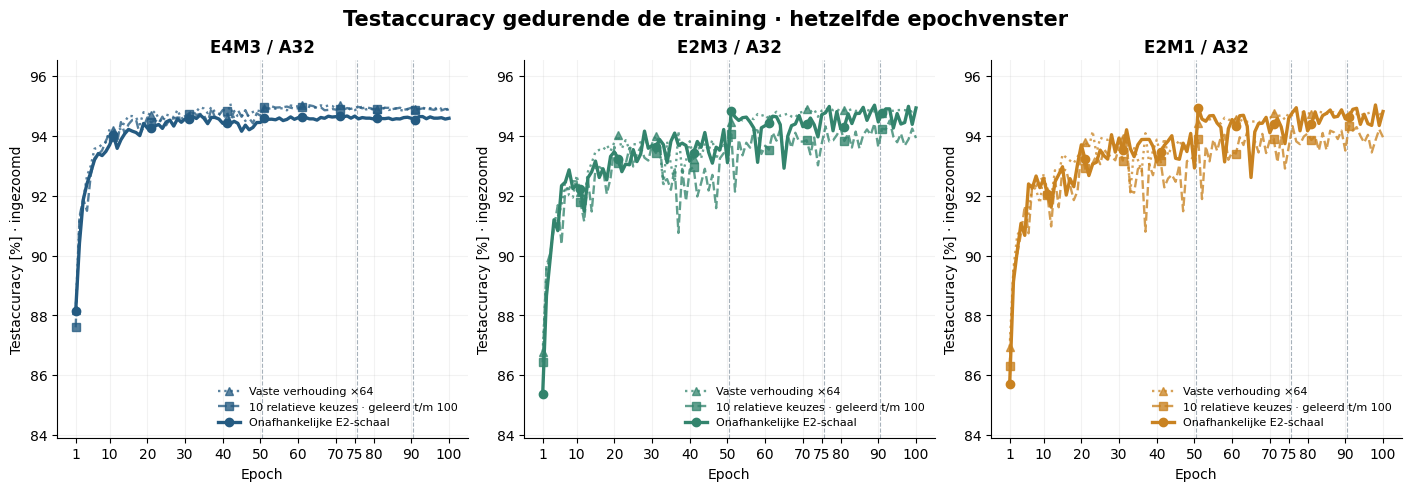

In [7]:
fig = h.plot_learning(run)
figures["01_accuracy_verloop"] = fig
display(fig)
plt.close(fig)

### Extra zoom op de laatste tien beschikbare epochs

Deze aanvullende grafiek vervangt de volledige curves hierboven niet. Alle punten in het gekozen venster blijven zichtbaar; er wordt niet gesmoothd.


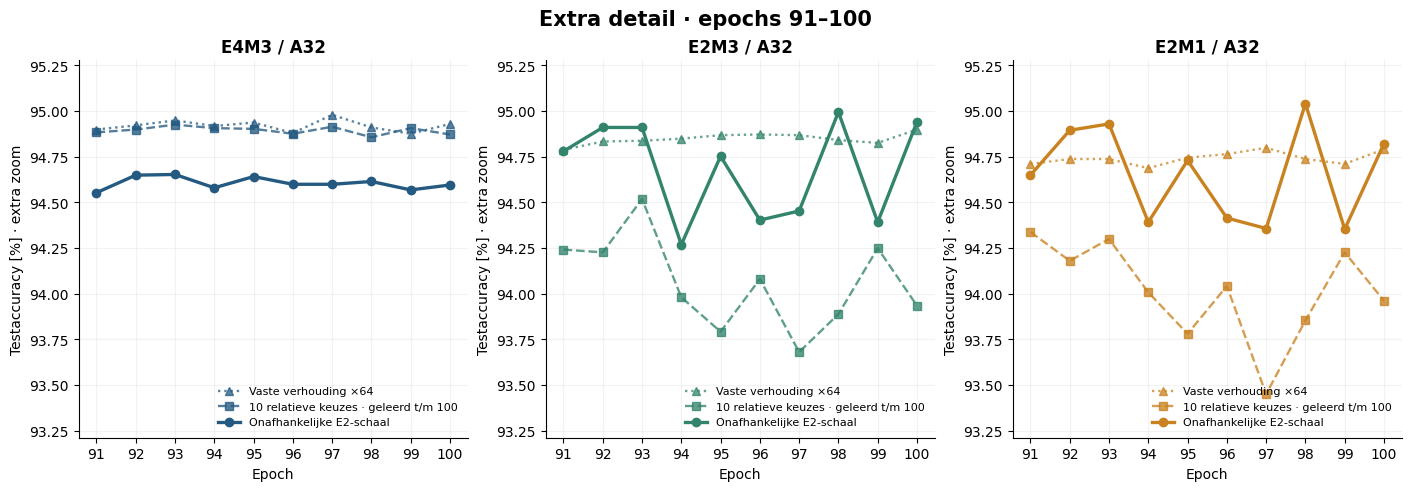

In [8]:
fig = h.plot_final_window(run, window=10)
figures["01b_accuracy_laatste10"] = fig
display(fig)
plt.close(fig)


### Epoch100 / actuele laatste epoch en selectie op beste E4M3

Links staat de laatste **gemeenschappelijke** epoch: bij een voltooide run epoch100, bij een gedeeltelijke run het werkelijk bereikte eindpunt. Rechts kiest elke variant de eerste hoogste E4M3-testaccuracy binnen datzelfde beschikbare venster. E2M3 en E2M1 komen steeds uit diezelfde gekozen epoch; er wordt geen afzonderlijk beste checkpoint per precisie gebruikt.

Bij voltooiing worden dus **epoch100** en **het gezamenlijke checkpoint gekozen op maximale E4M3-accuracy** vergeleken. Tijdens een gedeeltelijke run is de historische selectie binnen het kortere venster uit de metrics afgeleid, niet uit het beste checkpoint van de volledige referentietraining. Selectie op de officiële testset maakt die beste score geen onafhankelijke testschatting.

In [9]:
display(Markdown("**Laatste gemeenschappelijke epoch**"))
display(h.checkpoint_table(run, "last").round(4))
display(Markdown("**Beste E4M3 binnen hetzelfde venster**"))
display(h.checkpoint_table(run, "best").round(4))
display(Markdown("**Verschil op het gemeenschappelijke eindpunt** — procentpunten en aantallen testbeelden"))
display(h.difference_table(run).round(4))

**Laatste gemeenschappelijke epoch**

,Variant,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,Vaste verhouding ×64,100,gemeenschappelijk eindpunt,94.9293,24712,94.8986,24704,94.7910,24676
1,10 relatieve keuzes · geleerd t/m 100,100,gemeenschappelijk eindpunt,94.8717,24697,93.9344,24453,93.9613,24460
2,Onafhankelijke E2-schaal,100,gemeenschappelijk eindpunt,94.5951,24625,94.9408,24715,94.8218,24684


**Beste E4M3 binnen hetzelfde venster**

,Variant,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,Vaste verhouding ×64,42,eerste beste E4 in beschikbaar venster,95.0868,24753,93.8422,24429,93.9229,24450
1,10 relatieve keuzes · geleerd t/m 100,63,eerste beste E4 in beschikbaar venster,95.0292,24738,93.8460,24430,93.7001,24392
2,Onafhankelijke E2-schaal,34,eerste beste E4 in beschikbaar venster,94.7065,24654,93.1085,24238,93.3121,24291


**Verschil op het gemeenschappelijke eindpunt** — procentpunten en aantallen testbeelden

,Epoch,Referentie,Precisie,Onafhankelijk [%],Referentie [%],Verschil [procentpunt],Verschil correct [beelden]
0,100,Vaste verhouding ×64,E4M3,94.5951,94.9293,-0.3342,-87
1,100,Vaste verhouding ×64,E2M3,94.9408,94.8986,0.0423,11
2,100,Vaste verhouding ×64,E2M1,94.8218,94.7910,0.0307,8
3,100,10 relatieve keuzes · geleerd t/m 100,E4M3,94.5951,94.8717,-0.2766,-72
4,100,10 relatieve keuzes · geleerd t/m 100,E2M3,94.9408,93.9344,1.0065,262
5,100,10 relatieve keuzes · geleerd t/m 100,E2M1,94.8218,93.9613,0.8605,224


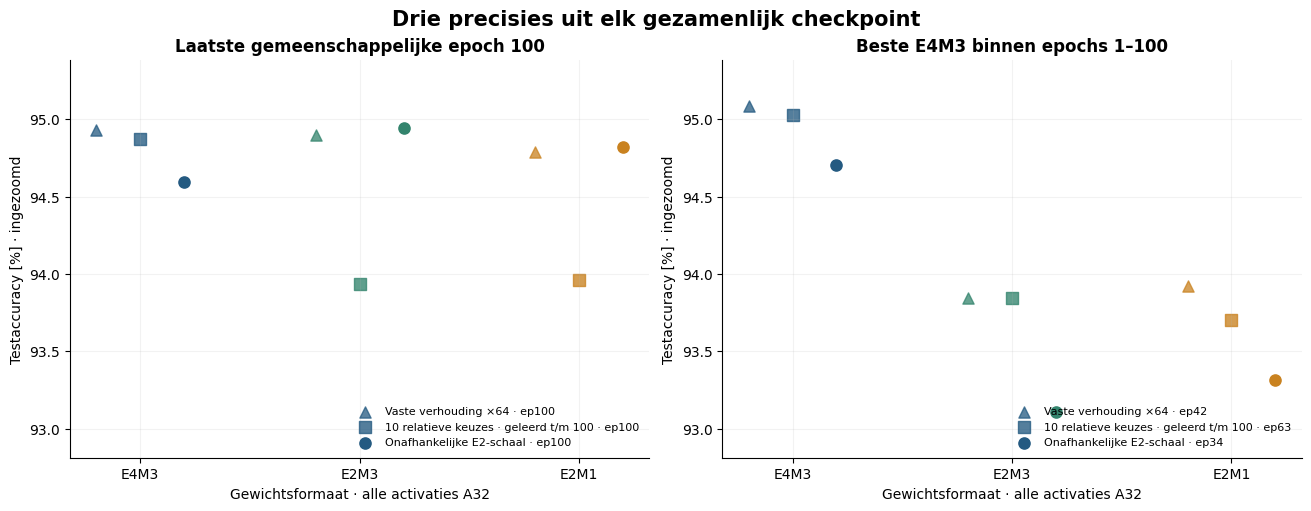

In [10]:
fig = h.plot_checkpoints(run)
figures["02_gemeenschappelijke_checkpoints"] = fig
display(fig)
plt.close(fig)

## 4. Welke schalen ontstaan?

Deze sectie scheidt de **geleerde absolute E2-exponent** van de **geobserveerde verhouding tot de bewegende E4-bronschaal**. Een verandering van die verhouding kan zowel door E2-leren als door een gewijzigde E4-bronschaal ontstaan.

De eerste grafiek vergelijkt initialisatie (epoch0) met de laatste beschikbare epoch. Daarna volgt de verdeling per epoch. Alle waargenomen verhoudingen worden getoond, ook waarden buiten de vroegere ×1…×512. Een niet-waargenomen waarde binnen een histogram betekent nul groepen; ontbrekende schaaldata worden nooit door nul vervangen.

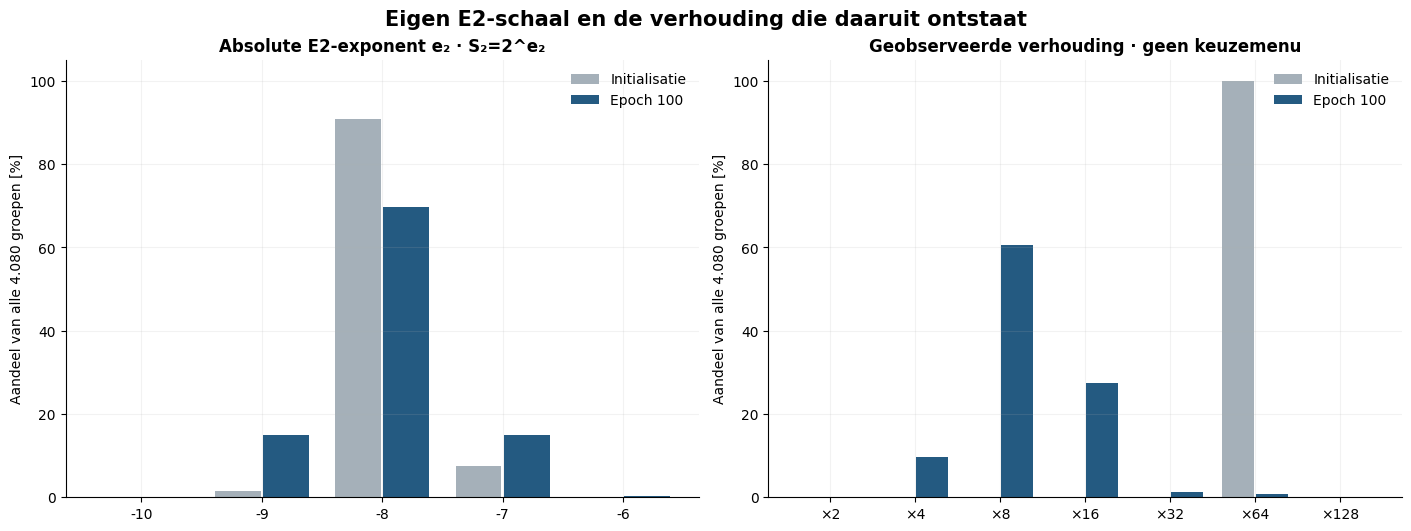

,Epoch,Geobserveerde Δ=e₂−e₄,Verhouding S₂/S₄,Groepen,Aandeel [%]
0,100,1,×2,1,0.0245
1,100,2,×4,395,9.6814
2,100,3,×8,2471,60.5637
3,100,4,×16,1122,27.5000
4,100,5,×32,51,1.2500
5,100,6,×64,33,0.8088
6,100,7,×128,7,0.1716


In [11]:
fig = h.plot_scale_distributions(run)
figures["03_schaalverdelingen_init_eind"] = fig
display(fig)
plt.close(fig)
display(h.scale_distribution_table(run).round(4))

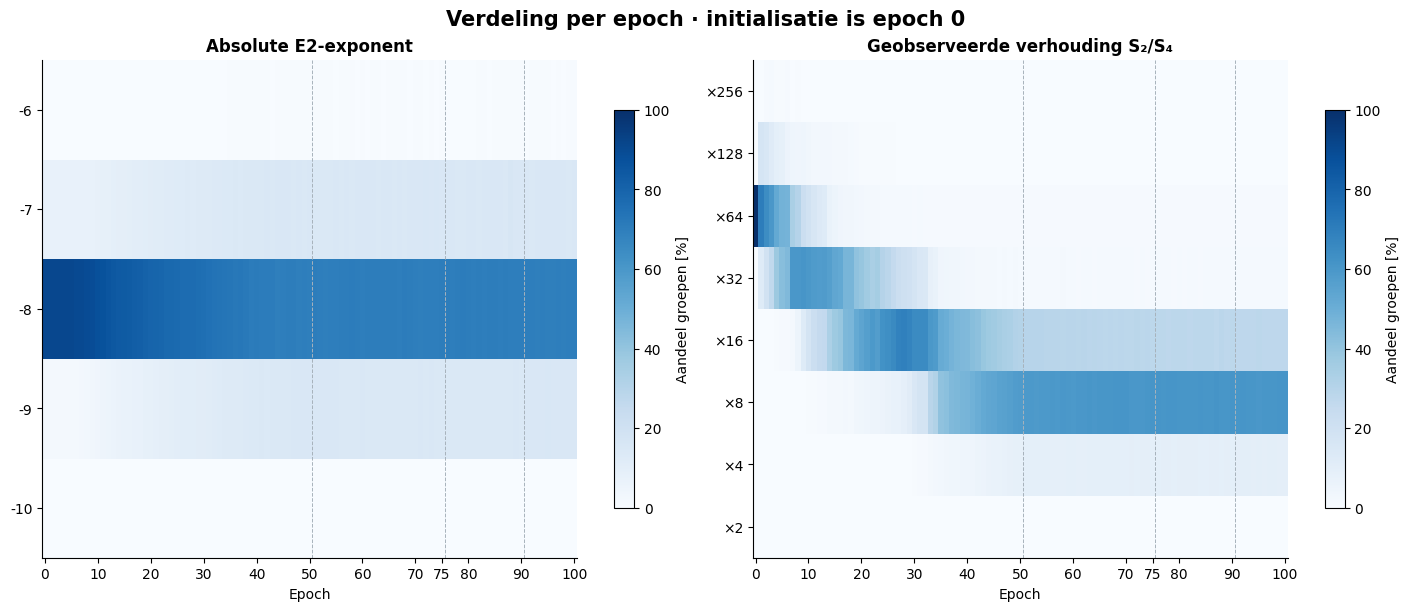

In [12]:
fig = h.plot_scale_evolution(run)
figures["04_schaalverdelingen_per_epoch"] = fig
display(fig)
plt.close(fig)

### Laagverschillen

De volgende curves tonen gemiddelden over groepen, geen betrouwbaarheidsintervallen. De tabel behoudt ook minimum en maximum; een gemiddelde alleen kan tegengestelde veranderingen tussen groepen verbergen.

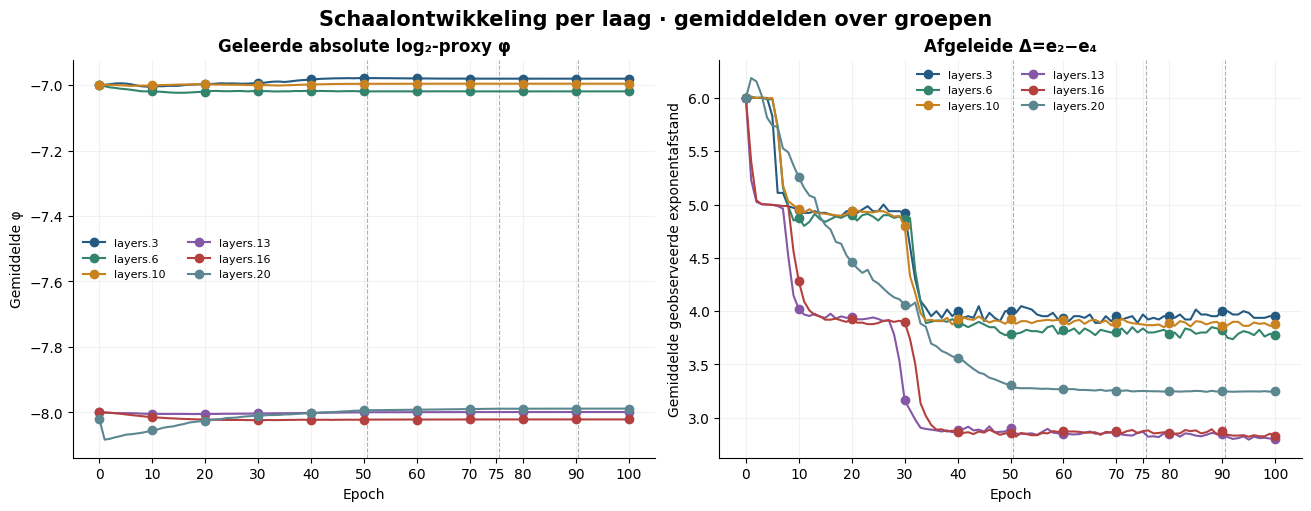

,layer,Groepen,phi_min,phi_gemiddeld,phi_max,E2_exponent_min,E2_exponent_max,geobserveerde_delta_min,geobserveerde_delta_max
0,layers.3,64,-7.76032,-6.98066,-6.50000,-8,-6,3,5
1,layers.6,80,-7.78810,-7.01945,-6.50000,-8,-6,3,5
2,layers.10,160,-7.57499,-6.99604,-6.50000,-8,-6,3,5
3,layers.13,288,-8.55067,-7.99863,-7.50000,-9,-7,2,4
4,layers.16,288,-8.52182,-8.02115,-7.49999,-9,-7,2,4
5,layers.20,3200,-9.65185,-7.98818,-6.30909,-10,-6,1,7


In [13]:
fig = h.plot_scale_by_layer(run)
figures["05_schalen_per_laag"] = fig
display(fig)
plt.close(fig)
display(h.scale_layer_table(run).round(5))

### Schaalveranderingen en gradientdiagnostiek

Links tellen we groepen waarvan de **opgeslagen waarde tussen twee opeenvolgende epochs** veranderde. Een groep die tussendoor heen en terug wisselde kan daar onzichtbaar blijven. Rechts staan daarom ook de tijdens de updates gemeten E2-wissels, inclusief terugwissels.

Een niet-nul proxyupdate hoeft niet meteen tot een andere harde exponent te leiden. Ook het omgekeerde geldt: een kleine update dicht bij een afrondingsgrens kan een discrete schaalwissel veroorzaken. Dat is een eigenschap van deze lokale surrogate-optimalisatie, geen bewijs dat expliciet alle exponenten zijn onderzocht.

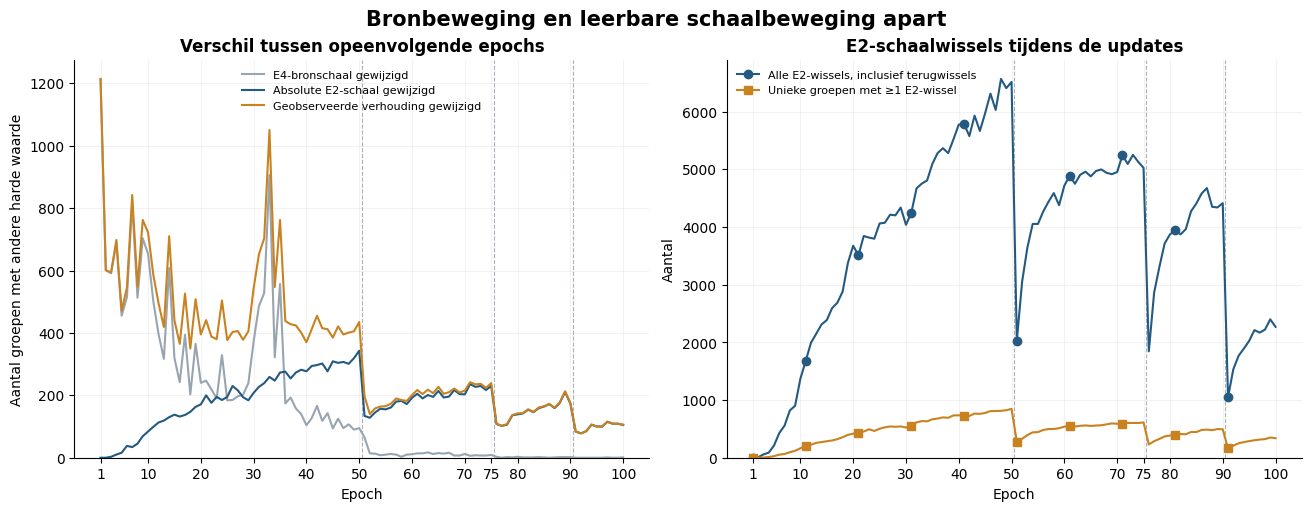

,Epoch,E4-bronschaal gewijzigd,Absolute E2-schaal gewijzigd,Geobserveerde verhouding gewijzigd
0,1,1214,0,1214
1,2,601,0,601
2,3,591,3,594
3,4,690,10,698
4,5,455,16,471
...,...,...,...,...
95,96,0,100,100
96,97,1,115,116
97,98,0,109,109
98,99,0,109,109


In [14]:
fig = h.plot_scale_changes(run)
figures["06_bron_en_e2_veranderingen"] = fig
display(fig)
plt.close(fig)
display(h.source_change_table(run))

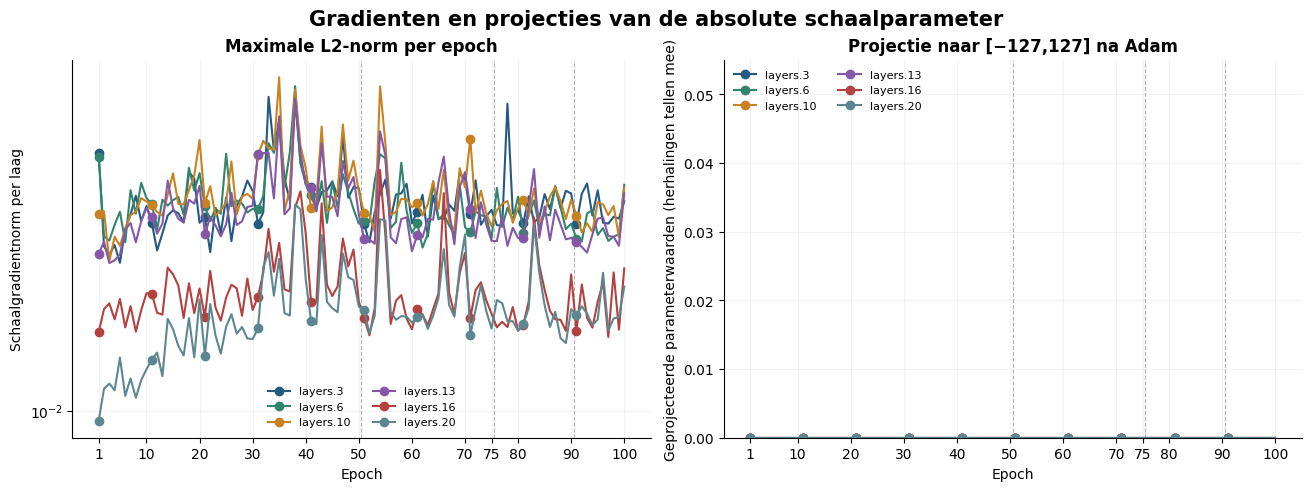

In [15]:
fig = h.plot_scale_gradients(run)
figures["07_gradient_en_projectie"] = fig
display(fig)
plt.close(fig)

## 5. Opslagkosten: wat kost de onafhankelijke schaal?

Per groep blijft één E4M3-broncode per gewichtspositie opgeslagen. Alle modi worden daaruit afgeleid. Alleen de schaalinformatie verschilt:

- **Vaste ×64:** één E4-schaalbyte; de E2-schaal wordt afgeleid.
- **Tien relatieve keuzes:** één E4-schaalbyte + vier bits keuze-informatie.
- **Onafhankelijke E2-schaal:** één E4-schaalbyte + één absolute E2-schaalbyte. E2M3 en E2M1 delen die tweede byte.

Bij 4.080 groepen is dit **4.080 bytes extra tegenover vaste ×64** en **2.040 bytes extra tegenover tien relatieve keuzes**. Beide schaalbanken samen kosten 0,5 bit per B32-positie; de eerste E4-bank is daarin meegeteld.

De onderstaande payloadberekening geldt voor de **zes MX-lagen inclusief groepspadding**. Zij sluit FP32-randlagen, BN-banken, bestandscontainerheaders, activaties en frameworkgeheugen uit. De training behoudt 4.080 FP32-proxies; proxy + gradient + twee Adam-momenten tellen analytisch 65.280 bytes, net als bij de tienkeuzemethode. Adam-stapmetadata en tijdelijke tensors vallen daarbuiten.

Deze getallen zijn **opslagberekeningen**, geen meting van geheugenverkeer, latency of energie. Hoeveel bytes bij precisiewissels werkelijk moeten worden opgehaald hangt ook van het opslag- en cachebeleid af; deze training meet dat niet.

,Variant,Groepen,E4-schaalbytes,Extra schaal/keuzebytes,Totaal schaalinformatie [bytes],Schaalinformatie [bit per B32-positie],"E4-codes + schaalinformatie, zes MX-lagen [bytes]",Extra training: proxy+grad+Adam [bytes]
0,Vaste ×64,4080,4080,0,4080,0.250,134640,0
1,10 relatieve keuzes,4080,4080,2040,6120,0.375,136680,65280
2,Onafhankelijke E2-schaal,4080,4080,4080,8160,0.500,138720,65280


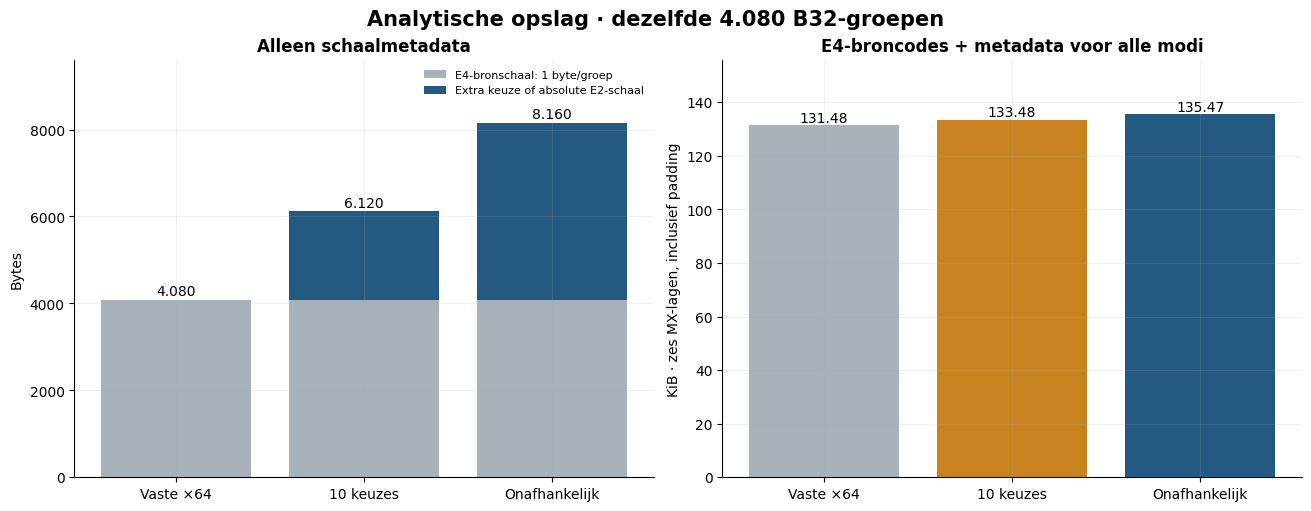

In [16]:
display(h.storage_cost_table(run))
fig = h.plot_storage_cost(run)
figures["08_opslagkosten"] = fig
display(fig)
plt.close(fig)

### Opgeslagen modelrepresentaties

De runner controleert de afgeleide gewichten tegen dezelfde live trainingsroute. Compacte bronexports bewaren de E4-codes en absolute lagere schaalbytes; zij bevatten geen masters van de zes MX-lagen en geen FP32-schaalproxies. Hervatbare trainingscheckpoints bewaren die FP32-toestand wel.

De tabel hieronder vermeldt **geserialiseerde containerbytes**, die ook hulpstaat en bestandsstructuur bevatten. Die zijn niet gelijk aan de theoretische schaalpayload uit de voorgaande grafiek. De exacte gewichtscontrole voert geen extra volledige testset-evaluatie uit.

In [17]:
display(h.export_table(run))

,Rol,Epoch,Precisie,Bestand,Containerbytes,Gewichten exact gereconstrueerd,MX-masters afwezig,FP32-schaalproxy afwezig,Afgeleid uit opgeslagen bron,Masters gelezen bij afleiding,Bron-SHA256
0,best_E4M3_test,34,E4M3,mx_source_MXFP8_E4M3_best.pt,202457,True,True,True,False,False,3f492b291ac1ebf4c0e1d3f1d587c4ce2573a13915d06b...
1,best_E4M3_test,34,E2M3,mx_derived_MXFP6_E2M3_best.pt,170521,True,True,True,True,False,3f492b291ac1ebf4c0e1d3f1d587c4ce2573a13915d06b...
2,best_E4M3_test,34,E2M1,mx_derived_MXFP4_E2M1_best.pt,137881,True,True,True,True,False,3f492b291ac1ebf4c0e1d3f1d587c4ce2573a13915d06b...
3,last_epoch,100,E4M3,mx_source_MXFP8_E4M3_last.pt,202457,True,True,True,False,False,1f6061eebcfbfd202ecc8c7fad096d28ecb3ad3ded3286...
4,last_epoch,100,E2M3,mx_derived_MXFP6_E2M3_last.pt,170521,True,True,True,True,False,1f6061eebcfbfd202ecc8c7fad096d28ecb3ad3ded3286...
5,last_epoch,100,E2M1,mx_derived_MXFP4_E2M1_last.pt,137881,True,True,True,True,False,1f6061eebcfbfd202ecc8c7fad096d28ecb3ad3ded3286...


## 6. Gemeten tijd en uitvoerbaarheid

Alleen werkelijk afgeronde epochs tellen als meting. Zolang deze run nog geen honderd complete epochs bevat, blijft een 100-epochtotaal een **projectie**. Na voltooiing toont de notebook het daadwerkelijk gemeten honderd-epochtotaal uit de opgeslagen epochtijden, ook wanneer de run tussentijds werd hervat.

De volledige training begint vanaf verse initialisatie; het pilotcheckpoint is geen warmstart.

**Gemeten:** 107.65 minuten voor 100 complete epochs, inclusief train, test en checkpoints. Dit is het **werkelijk gemeten honderd-epochtotaal: 1.79 uur**, opgebouwd uit de opgeslagen epochtijden.

Voorbereiding van data, installatie en uiteindelijke rapportexport vallen buiten de epochtijden. Gedeeltelijke runs meten de toekomstige LR-overgangen en langdurige thermische belasting nog niet volledig. Ook een gemeten complete duur garandeert niet dezelfde duur bij een volgende training.

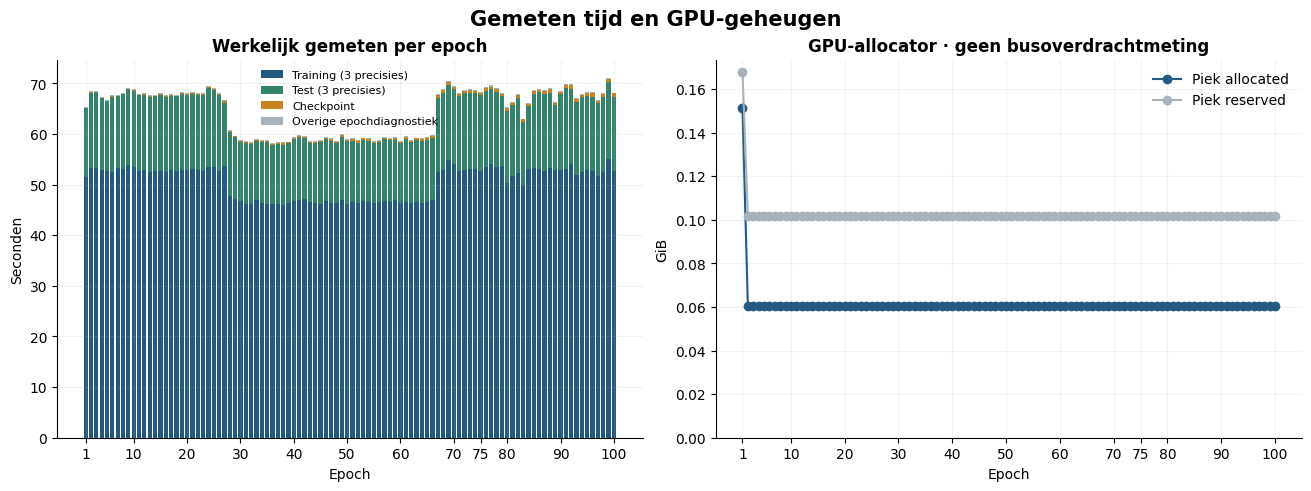

In [18]:
display(Markdown(h.timing_markdown(run)))
fig = h.plot_timing(run)
figures["09_tijd_en_gpugeheugen"] = fig
display(fig)
plt.close(fig)

## 7. Controles, herkomst en interpretatie

**Wat deze training kan aantonen:** de accuracy en de schaalontwikkeling op epoch100 onder dit protocol, het verschil met de historische vaste en relatieve schaalvarianten, en gedrag rond de LR-overgangen.

**Wat één run niet aantoont:** onafhankelijkheid van initialisatie, statistische significantie van kleine verschillen, het globale optimum van de schalen, of een hardwareversnelling. Hetzelfde beginpunt als de pilot is hier bewust behouden; alleen de duur is uitgebreid. Een eigen E2-schaal betekent onafhankelijkheid van de actuele E4-schaal, terwijl de lagere elementcodes uit de E4-bron blijven komen.

De codebestanden en de gelezen meetbestanden zijn de primaire bronnen. Historische referenties worden via `REFERENCE.json` en hashes gecontroleerd. Voor de relatieve 100-epochreferentie en de onafhankelijke pilot kan ook de samplevolgorde worden gecontroleerd; bij de vaste referentie ontbreekt de volledige history in dit pakket. Het epoch50-checkpoint wordt bewaard voor een eventuele latere afzonderlijke freezeproef; in deze run blijft φ doorleren.

Onderstaande audit maakt ontbrekende of conflicterende informatie zichtbaar.

In [19]:
display(h.audit_table(run))
display(h.reference_table(run))
display(h.diagnostics_table(run))

,Controle,Opgeslagen resultaat / analyse
0,Rapportstatus,PASS
1,Metrics consistent met geschiedenis,True
2,Schaalstaten en bitexponenten consistent,True
3,Checkpointselectie gecontroleerd,True
4,Historische referenties geverifieerd,True
5,FP32-masters en Adam-momenten,True
6,Eén E4-bron per laag en minibatch,True
7,E2M1-schaal identiek aan E2M3,True
8,Cache leeg vóór optimizerupdates,True
9,Evaluatie zonder optimizerupdates,True


,Referentie,Bronrun,Beschikbare epochs,Rol,Bestand,Marker SHA256,Vergelijking met nieuwe run gevalideerd
0,10 relatieve keuzes · geleerd t/m 100,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,100,hoofdvergelijking op dezelfde beschikbare epochs,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,1198b78a9ce247fb0ae5c712f0ae63a7975a555e95dffc...,True
1,Vaste verhouding ×64,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,100,hoofdvergelijking op dezelfde beschikbare epochs,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,a323762894db83b15af10e79a8aff0128c50f7946805a0...,True
2,Onafhankelijke E2-schaal · eerdere vijfepochpilot,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,5,aparte pilotherkomst; nooit een 100-epochcompe...,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,a0d1ea4e5b3fce20ead37b9ed476a050360f966b4055a7...,True


,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 8. Optioneel: figuren bewaren

Standaard blijft deze stap uitgeschakeld. Met `SAVE_FIGURES = True` komen PNG- en PDF-bestanden plus een herkomstbestand in een nieuwe map naast de resultaten. Ruwe data en eerdere figuren worden niet overschreven.

In [20]:
if SAVE_FIGURES:
    saved = h.save_figures(figures, run)
    print("Nieuwe figurenmap:", saved)
else:
    print("Figuren alleen weergegeven; niets opgeslagen.")

Figuren alleen weergegeven; niets opgeslagen.
